# 8. 교차검증으로 임계값 다시 정하기

06, 07 노트북은 테스트셋 결과를 보면서 임계값을 골랐기 때문에 테스트 성능이 낙관적으로 나왔을 수 있다.
여기서는 임계값을 학습 데이터 안의 교차검증(OOF 예측 확률)으로만 정하고, 테스트셋은 마지막에 한 번만 평가한다.

- 분할은 06, 07과 동일 (random_state=42, stratify) → 같은 테스트셋
- 학습 데이터에서 5-fold x 3회 반복 교차검증, 전처리도 fold마다 새로 학습
- 모델 파라미터는 06 XGBoost1, 07 LightGBM1과 동일

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from lightgbm import LGBMClassifier
from sklearn.impute import SimpleImputer
from sklearn.metrics import (
    average_precision_score,
    confusion_matrix,
    f1_score,
    precision_score,
    recall_score,
    roc_auc_score,
)
from sklearn.model_selection import RepeatedStratifiedKFold, train_test_split
from xgboost import XGBClassifier

# 현재 폴더부터 상위로 올라가며 data 폴더 탐색
data_dir = next(p / 'data' for p in [Path.cwd(), *Path.cwd().parents] if (p / 'data' / 'secom.data').exists())
results_dir = data_dir.parent / "results"

X_raw = pd.read_csv(data_dir / "secom.data", sep=r"\s+", header=None)
labels = pd.read_csv(data_dir / "secom_labels.data", sep=r"\s+", header=None)
y = (labels[0] == 1).astype(int)  # PASS=0, FAIL=1

X_train_raw, X_test_raw, y_train, y_test = train_test_split(
    X_raw, y, test_size=0.2, random_state=42, stratify=y
)

# 06 노트북 결과와 테스트셋이 같은지 확인
saved = pd.read_csv(results_dir / "06XGBoost1.csv")
assert (saved["y_true"].values == y_test.values).all(), "06 노트북과 테스트셋이 다릅니다"
print(f"학습 {X_train_raw.shape}, 테스트 {X_test_raw.shape}, 학습 불량 {y_train.sum()}개, 테스트 불량 {y_test.sum()}개")

학습 (1253, 590), 테스트 (314, 590), 학습 불량 83개, 테스트 불량 21개


In [2]:
def preprocess(train, other):
    """train에서만 결측 필터, 중앙값, 단일값 제거 기준을 학습해 두 데이터에 적용"""
    cols = train.columns[train.isna().mean() < 0.8]
    imputer = SimpleImputer(strategy="median").fit(train[cols])
    tr = pd.DataFrame(imputer.transform(train[cols]), columns=cols, index=train.index)
    ot = pd.DataFrame(imputer.transform(other[cols]), columns=cols, index=other.index)
    cols = tr.columns[tr.nunique() > 1]
    return tr[cols], ot[cols]


def make_models(pos_weight):
    # 06 XGBoost1, 07 LightGBM1과 같은 파라미터
    # LightGBM의 subsample은 subsample_freq가 0이면 적용되지 않음 (비교를 위해 그대로 둠)
    return {
        "XGBoost": XGBClassifier(
            n_estimators=100, max_depth=3, learning_rate=0.05,
            scale_pos_weight=pos_weight, subsample=0.8, colsample_bytree=0.5,
            random_state=42, eval_metric="logloss", n_jobs=-1,
        ),
        "LightGBM": LGBMClassifier(
            n_estimators=100, learning_rate=0.05, num_leaves=15, max_depth=4,
            scale_pos_weight=pos_weight, subsample=0.8, colsample_bytree=0.5,
            random_state=42, verbosity=-1, n_jobs=-1,
        ),
    }

## 학습 데이터 교차검증 (OOF 예측 확률 수집)

In [3]:
N_SPLITS, N_REPEATS = 5, 3
cv = RepeatedStratifiedKFold(n_splits=N_SPLITS, n_repeats=N_REPEATS, random_state=42)
oof = {name: np.zeros((N_REPEATS, len(y_train))) for name in ["XGBoost", "LightGBM"]}
fold_scores = []

for i, (tr_idx, va_idx) in enumerate(cv.split(X_train_raw, y_train)):
    X_tr, X_va = preprocess(X_train_raw.iloc[tr_idx], X_train_raw.iloc[va_idx])
    y_tr, y_va = y_train.iloc[tr_idx], y_train.iloc[va_idx]
    pos_weight = (y_tr == 0).sum() / (y_tr == 1).sum()
    for name, model in make_models(pos_weight).items():
        prob = model.fit(X_tr, y_tr).predict_proba(X_va)[:, 1]
        oof[name][i // N_SPLITS, va_idx] = prob
        fold_scores.append({
            "model": name,
            "PR-AUC": average_precision_score(y_va, prob),
            "ROC-AUC": roc_auc_score(y_va, prob),
        })

fold_df = pd.DataFrame(fold_scores)
print(f"fold 15개 기준 (PR-AUC 무작위 기준선 = 불량 비율 {y_train.mean():.3f})")
display(fold_df.groupby("model").agg(["mean", "std", "min", "max"]).round(3))

fold 15개 기준 (PR-AUC 무작위 기준선 = 불량 비율 0.066)


PR-AUC                      ROC-AUC                     
           mean    std    min    max    mean    std    min    max
model                                                            
LightGBM  0.169  0.062  0.078  0.335   0.685  0.058  0.583  0.764
XGBoost   0.188  0.062  0.073  0.285   0.702  0.073  0.576  0.791

## OOF 확률로 임계값 선택

반복 3회 각각의 OOF 예측으로 지표를 계산하고 평균을 낸다. 기준은 FAIL F1 최대.

In [4]:
thresholds = np.round(np.arange(0.05, 0.61, 0.05), 2)
rows = []
for name, probs in oof.items():
    for th in thresholds:
        preds = [(p >= th).astype(int) for p in probs]
        f1s = [f1_score(y_train, pr) for pr in preds]
        rows.append({
            "model": name,
            "threshold": th,
            "FAIL Recall": np.mean([recall_score(y_train, pr) for pr in preds]),
            "FAIL Precision": np.mean([precision_score(y_train, pr, zero_division=0) for pr in preds]),
            "FAIL F1": np.mean(f1s),
            "F1 std": np.std(f1s),
        })
th_df = pd.DataFrame(rows)
best = th_df.loc[th_df.groupby("model")["FAIL F1"].idxmax()].set_index("model")

display(th_df.pivot(index="threshold", columns="model", values=["FAIL Recall", "FAIL Precision", "FAIL F1"]).round(3))
print("CV로 고른 임계값")
display(best.round(3))

FAIL Recall         FAIL Precision          FAIL F1        
model        LightGBM XGBoost       LightGBM XGBoost LightGBM XGBoost
threshold                                                            
0.05            0.775   0.952          0.097   0.075    0.173   0.140
0.10            0.594   0.827          0.119   0.093    0.198   0.167
0.15            0.454   0.691          0.130   0.107    0.202   0.185
0.20            0.357   0.546          0.145   0.119    0.206   0.195
0.25            0.293   0.470          0.162   0.142    0.208   0.218
0.30            0.217   0.369          0.163   0.149    0.186   0.213
0.35            0.173   0.337          0.164   0.186    0.168   0.240
0.40            0.137   0.253          0.182   0.197    0.156   0.221
0.45            0.112   0.193          0.206   0.205    0.145   0.198
0.50            0.088   0.153          0.238   0.245    0.129   0.188
0.55            0.036   0.088          0.167   0.215    0.059   0.125
0.60            0.024   0.052          0.169   0.220    0.042   0.084

CV로 고른 임계값


,threshold,FAIL Recall,FAIL Precision,FAIL F1,F1 std
model,,,,,
LightGBM,0.25,0.293,0.162,0.208,0.023
XGBoost,0.35,0.337,0.186,0.240,0.029


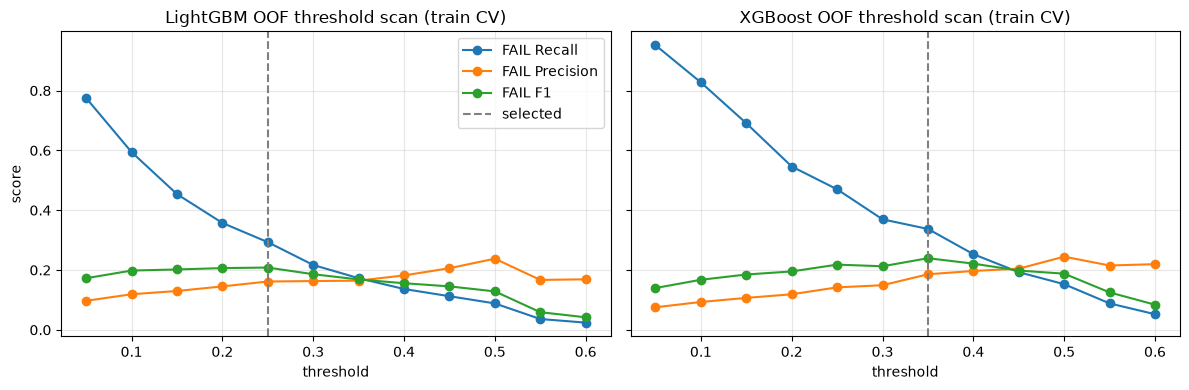

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)
for ax, (name, g) in zip(axes, th_df.groupby("model")):
    for col in ["FAIL Recall", "FAIL Precision", "FAIL F1"]:
        ax.plot(g["threshold"], g[col], marker="o", label=col)
    ax.axvline(best.loc[name, "threshold"], color="gray", linestyle="--", label="selected")
    ax.set_title(f"{name} OOF threshold scan (train CV)")
    ax.set_xlabel("threshold")
    ax.grid(alpha=0.3)
axes[0].set_ylabel("score")
axes[0].legend()
plt.tight_layout()
plt.show()

## 전체 학습 데이터로 재학습 후 테스트셋 1회 평가

In [6]:
X_tr, X_te = preprocess(X_train_raw, X_test_raw)
pos_weight = (y_train == 0).sum() / (y_train == 1).sum()

final_rows = []
for name, model in make_models(pos_weight).items():
    prob = model.fit(X_tr, y_train).predict_proba(X_te)[:, 1]
    th = best.loc[name, "threshold"]
    pred = (prob >= th).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_test, pred, labels=[0, 1]).ravel()
    final_rows.append({
        "model": name,
        "CV threshold": th,
        "PR-AUC": average_precision_score(y_test, prob),
        "ROC-AUC": roc_auc_score(y_test, prob),
        "FAIL Recall": recall_score(y_test, pred),
        "FAIL Precision": precision_score(y_test, pred, zero_division=0),
        "FAIL F1": f1_score(y_test, pred),
        "잡은 불량(21개 중)": tp,
        "오탐(293개 중)": fp,
    })
    pd.DataFrame({"y_true": y_test.values, "y_pred": pred}).to_csv(
        results_dir / f"08{name}_cv.csv", index=False
    )

final_df = pd.DataFrame(final_rows).set_index("model")
display(final_df.round(3))

,CV threshold,PR-AUC,ROC-AUC,FAIL Recall,FAIL Precision,FAIL F1,잡은 불량(21개 중),오탐(293개 중)
model,,,,,,,,
XGBoost,0.35,0.234,0.748,0.476,0.27,0.345,10,27
LightGBM,0.25,0.169,0.698,0.333,0.20,0.250,7,28


## 정리

- 학습 데이터 CV에서 FAIL F1이 가장 높은 임계값은 XGBoost 0.35, LightGBM 0.25
- 그 임계값으로 테스트셋을 한 번 평가한 결과 XGBoost가 불량 21개 중 10개 검출, 오탐 27개 (F1 0.345)
- 06에서 테스트셋을 보고 고른 0.3(12개 검출, 오탐 40개)보다 덜 잡지만 오탐이 줄었고, 이쪽이 누수 없는 수치
- 다만 같은 임계값에서 CV가 예상한 Recall은 0.34, 테스트는 0.48. 테스트 불량이 21개뿐이라 이번 분할이 운 좋게 나온 쪽이고 현실적인 기대치는 CV 쪽
- PR-AUC는 fold별 0.07~0.29로 편차가 크다. 무작위 기준선(0.066)보다는 확실히 높지만 아직 실사용 수준은 아님
- 두 모델 중에서는 XGBoost가 근소하게 앞섬